## **Trabajo Práctico Final: Airbnb Price - Machine Learning**
____
__Universidad Tecnológica Nacional, Buenos Aires__\
__Ingeniería Industrial__\
__Ciencia de Datos - Curso I5521__
____

- Nombre: Facundo
- Apellido: Del Bono

En este notebook entrenamos modelos de regresión para predecir el precio por noche de las propiedades de Airbnb. Después aplicamos PCA para reducir la dimensionalidad y volvemos a predecir.

# Librerías

In [1]:
# Importo librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.decomposition import PCA

# LightGBM no viene con Anaconda: si no está instalado, correr en la terminal: pip install lightgbm
import lightgbm as lgb

# Dataset

In [2]:
# Cargo el dataset limpio que guarde en el notebook del EDA
df = pd.read_csv('airbnb_limpio.csv')

# Muestro las primeras 5 filas
df.head()

,property_type,room_type,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,host_has_profile_pic,host_identity_verified,...,n_amenities,am_tv,am_kitchen,am_fireplace,am_gym,am_pool,am_doorman,tiene_reviews,largo_descripcion,log_price
0,House,Entire home/apt,4,1.0,Real Bed,flexible,1,SF,1.0,1.0,...,15,1,1,1,0,0,0,0,468,6.620073
1,Apartment,Entire home/apt,2,1.0,Real Bed,moderate,1,DC,1.0,1.0,...,12,1,1,0,0,0,0,1,699,4.744932
2,Apartment,Private room,2,1.0,Real Bed,strict,1,SF,1.0,1.0,...,10,1,0,0,0,0,0,1,1000,4.442651
3,House,Private room,2,1.0,Real Bed,moderate,1,SF,1.0,0.0,...,21,1,0,0,0,0,0,1,1000,4.787492
4,Apartment,Entire home/apt,6,1.5,Real Bed,strict,1,DC,1.0,1.0,...,25,1,1,0,0,0,0,1,1000,5.298317


In [3]:
# Cantidad de filas y columnas
print(df.shape)

(19243, 31)


In [4]:
# Usamos el dataset que ya limpiamos en el EDA: 19243 publicaciones, sin valores nulos
# Tiene 31 columnas: las 30 del dataset limpio más log_price, que creamos en el EDA

# Variables X e y

In [5]:
# y es lo que queremos predecir: el logaritmo del precio
y = df['log_price']

# X son las características de las propiedades
# Saco price y log_price porque son la respuesta, y neighbourhood porque tiene demasiados valores distintos
X = df.drop(columns=['price', 'log_price', 'neighbourhood'])

print(X.shape)
print(y.shape)

(19243, 28)
(19243,)


In [6]:
# Cuento cuántos barrios distintos hay
print(df['neighbourhood'].nunique())

279


In [7]:
# Predecimos log(precio) y no el precio directo porque, como vimos en el EDA, el precio es muy asimétrico y el log lo vuelve casi simétrico
# Sacamos neighbourhood porque tiene 279 barrios distintos: se convertirían en 279 columnas nuevas, muchas con muy pocas publicaciones
# La ubicación ya está representada por city, latitude y longitude
# Nos quedan 28 variables para predecir el precio

# Variables categóricas

In [8]:
# Veo qué columnas son de texto 
X.dtypes

property_type                 str
room_type                     str
accommodates                int64
bathrooms                 float64
bed_type                      str
cancellation_policy           str
cleaning_fee                int64
city                          str
host_has_profile_pic      float64
host_identity_verified    float64
host_response_rate        float64
instant_bookable            int64
latitude                  float64
longitude                 float64
number_of_reviews           int64
review_scores_rating      float64
bedrooms                  float64
beds                      float64
host_antiguedad           float64
n_amenities                 int64
am_tv                       int64
am_kitchen                  int64
am_fireplace                int64
am_gym                      int64
am_pool                     int64
am_doorman                  int64
tiene_reviews               int64
largo_descripcion           int64
dtype: object

In [9]:
# Hay 5 variables categóricas (su tipo de dato es str): property_type, room_type, bed_type, cancellation_policy y city

In [10]:
# Cantidad de publicaciones por tipo de propiedad
X['property_type'].value_counts()

property_type
Apartment             11468
House                  4789
Condominium            1566
Townhouse               500
Loft                    205
Other                   168
Bed & Breakfast         134
Guest suite              65
In-law                   64
Guesthouse               54
Boutique hotel           47
Dorm                     46
Timeshare                33
Boat                     30
Hostel                   16
Bungalow                 13
Villa                    11
Camper/RV                10
Cabin                     8
Castle                    4
Serviced apartment        3
Treehouse                 3
Yurt                      2
Tent                      1
Train                     1
Vacation home             1
Cave                      1
Name: count, dtype: int64

In [11]:
# Agrupo los tipos de propiedad con menos de 30 publicaciones en la categoría 'Other' que ya existe
conteo = X['property_type'].value_counts()
tipos_raros = conteo[conteo < 30].index
X.loc[X['property_type'].isin(tipos_raros), 'property_type'] = 'Other'

# Verifico cómo quedó
X['property_type'].value_counts()

property_type
Apartment          11468
House               4789
Condominium         1566
Townhouse            500
Other                242
Loft                 205
Bed & Breakfast      134
Guest suite           65
In-law                64
Guesthouse            54
Boutique hotel        47
Dorm                  46
Timeshare             33
Boat                  30
Name: count, dtype: int64

In [12]:
#Hay 27 tipos de propiedad, pero muchos tienen muy pocas publicaciones
#Con tan pocos casos el modelo no puede aprender nada de esa categoría, por lo tanto, agrupamos las demás en 'Other'
#Quedan 14 tipos de propiedad

In [13]:
# Separo las columnas categóricas (texto) de las numéricas
columnas_categoricas = ['property_type', 'room_type', 'bed_type', 'cancellation_policy', 'city']
columnas_numericas = X.drop(columns=columnas_categoricas).columns

print(len(columnas_numericas))
print(len(columnas_categoricas))

23
5


In [14]:
# Tenemos 23 variables numéricas y 5 categóricas
# Ya no usamos pd.get_dummies antes de separar train y test: las dummies se crean dentro del Pipeline, solo con los datos de train

# Train y test

In [15]:
# Separo los datos: 80% para entrenar (train) y 20% para evaluar (test)
# random_state fija la separación para que siempre salga igual cada vez que corro el notebook
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)

(15394, 28)
(3849, 28)


In [16]:
# Train tiene 15394 publicaciones y test 3849
# Usamos 80/20 porque tenemos muchos datos: alcanza para entrenar bien y el test es lo suficientemente grande para evaluar

# Preprocesamiento: Pipeline y ColumnTransformer

In [17]:
# Para las categóricas armo una secuencia: primero las paso a dummies y después las estandarizo
# handle_unknown='ignore' evita errores si en test aparece una categoría que no estaba en train
transformador_cat = Pipeline([('dummies', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
                              ('escalado', StandardScaler())])

# ColumnTransformer: aplica una transformación distinta a cada grupo de columnas
# numéricas -> estandarización (media 0 y desvío 1)
# categóricas -> dummies + estandarización
preprocesador = ColumnTransformer([
    ('num', StandardScaler(), columnas_numericas),
    ('cat', transformador_cat, columnas_categoricas)],
    verbose_feature_names_out=False)

In [18]:
# Para ver cómo quedan los datos, ajusto el preprocesador con train y transformo train
X_train_prep = preprocesador.fit_transform(X_train)
nombres_columnas = preprocesador.get_feature_names_out()

print(X_train_prep.shape)
pd.DataFrame(X_train_prep, columns=nombres_columnas).describe().loc[['mean', 'std']].round(2)

(15394, 54)


,accommodates,bathrooms,cleaning_fee,host_has_profile_pic,host_identity_verified,host_response_rate,instant_bookable,latitude,longitude,number_of_reviews,...,bed_type_Real Bed,cancellation_policy_flexible,cancellation_policy_moderate,cancellation_policy_strict,cancellation_policy_super_strict_30,cancellation_policy_super_strict_60,city_Boston,city_Chicago,city_DC,city_SF
mean,0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,0.0,...,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [19]:
# Después del preprocesamiento quedan 54 columnas: 23 numéricas y 31 dummies (una por cada categoría)
# Todas quedaron con media 0 y desvío 1, para que ninguna variable pese más que otra solo por tener números más grandes
# Por qué usamos Pipeline y ColumnTransformer (clase 07):
# - El preprocesador se ajusta solo con train, y se aplica a test con lo que aprendió de train (sin data leakage)
# - Al meter el preprocesador dentro de cada modelo, en cada fold de la cross-validation también se ajusta solo con los datos de entrenamiento de ese fold
# - Todos los modelos usan exactamente el mismo preprocesamiento, sin repetir código

# Métricas

In [20]:
# Función para evaluar un modelo ya entrenado
def evaluar(nombre, modelo, X_tr, X_te):
    # Predicciones en train y en test 
    pred_train = modelo.predict(X_tr)
    pred_test = modelo.predict(X_te)

    # R2 en train y en test
    r2_train = r2_score(y_train, pred_train)
    r2_test = r2_score(y_test, pred_test)

    # Paso el precio real y el predicho de log a dólares con la exponencial
    precio_real = np.exp(y_test)
    precio_pred = np.exp(pred_test)

    # Errores en dólares
    rmse = np.sqrt(mean_squared_error(precio_real, precio_pred))
    mae = mean_absolute_error(precio_real, precio_pred)

    return {'Modelo': nombre, 'R2 train': r2_train, 'R2 test': r2_test, 'RMSE (USD)': rmse, 'MAE (USD)': mae}

# Lista donde voy a guardar los resultados de cada modelo
resultados = []

In [21]:
# Creamos una función para evaluar todos los modelos de la misma forma. 
# R2: qué porcentaje de la variación del log(precio) explica el modelo (si da 1 es perfecto, si da 0 no explica nada). Lo calculamos en train y en test para detectar overfitting
# RMSE: error promedio en dólares, penaliza más los errores grandes
# MAE: error promedio en dólares, todos los errores pesan igual
# El modelo predice log(precio), por eso para RMSE y MAE volvemos a dólares

# Baseline: mediana por ciudad y tipo de habitación

In [22]:
# Regla simple sin Machine Learning: predecir para cada publicación la mediana del log(precio)
# de las publicaciones de train de su misma ciudad y tipo de habitación
train_base = X_train[['city', 'room_type']].copy()
train_base['log_price'] = y_train
medianas = train_base.groupby(['city', 'room_type'])['log_price'].median()
print(medianas)

city     room_type      
Boston   Entire home/apt    5.192957
         Private room       4.310777
         Shared room        4.196947
Chicago  Entire home/apt    4.882802
         Private room       4.094345
         Shared room        3.433987
DC       Entire home/apt    5.010635
         Private room       4.369448
         Shared room        3.806662
SF       Entire home/apt    5.416100
         Private room       4.605170
         Shared room        4.248495
Name: log_price, dtype: float64


In [23]:
# Predicciones: busco la mediana que corresponde a cada publicación
pred_base_train = X_train.set_index(['city', 'room_type']).index.map(medianas)
pred_base_test = X_test.set_index(['city', 'room_type']).index.map(medianas)

# Calculo las mismas métricas que en la función evaluar
res_base = {'Modelo': 'Baseline (mediana ciudad x tipo)',
            'R2 train': r2_score(y_train, pred_base_train),
            'R2 test': r2_score(y_test, pred_base_test),
            'RMSE (USD)': np.sqrt(mean_squared_error(np.exp(y_test), np.exp(pred_base_test))),
            'MAE (USD)': mean_absolute_error(np.exp(y_test), np.exp(pred_base_test))}
resultados.append(res_base)
pd.DataFrame([res_base]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Baseline (mediana ciudad x tipo),0.341,0.347,200.564,93.502


In [24]:
# El baseline es una regla simple sin Machine Learning: predecir la mediana de la ciudad y el tipo de habitación
# Explica el 34,7% de la variación del precio y se equivoca en promedio 93,5 USD por noche
# Sirve como piso: un modelo de Machine Learning solo vale la pena si le gana a esta regla

# Regresión lineal

In [25]:
# Pipeline: primero el preprocesador y después el modelo
lr = Pipeline([('prep', preprocesador), ('modelo', LinearRegression())])
lr.fit(X_train, y_train)

# Evalúo el modelo y guardo el resultado
res_lr = evaluar('Regresión lineal', lr, X_train, X_test)
resultados.append(res_lr)
pd.DataFrame([res_lr]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Regresión lineal,0.579,0.577,164.42,78.073


In [26]:
# La regresión lineal explica el 57,7% de la variación del precio en test y se equivoca en promedio 78 USD por noche
# Le gana claramente al baseline (34,7%)
# El R2 en train (0.579) y en test (0.577) son casi iguales, por lo que podemos decir que no hay overfitting

# Ridge

In [27]:
# Valores de alpha que voy a probar. Dentro de un Pipeline el nombre es 'modelo__alpha'
param_ridge = {'modelo__alpha': [0.01, 0.1, 1, 10, 100, 1000]}

ridge = Pipeline([('prep', preprocesador), ('modelo', Ridge())])
grid_ridge = GridSearchCV(ridge, param_ridge, cv=5, scoring='r2')
grid_ridge.fit(X_train, y_train)

print(grid_ridge.best_params_)
print(grid_ridge.best_score_)

{'modelo__alpha': 0.01}
0.5749244811055918


In [28]:
res_ridge = evaluar('Ridge', grid_ridge.best_estimator_, X_train, X_test)
resultados.append(res_ridge)
pd.DataFrame([res_ridge]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Ridge,0.579,0.577,164.33,78.096


In [29]:
# GridSearchCV eligió alpha = 0.01, el valor más chico
# Ridge da el mismo resultado que la regresión lineal (R2 test = 0.577)
# Tiene sentido ya que Ridge sirve para evitar el overfitting, y la regresión lineal no tenía overfitting

# Árbol de decisión

In [30]:
param_arbol = {'modelo__max_depth': [5, 10, 15, 20],
               'modelo__min_samples_leaf': [10, 20, 50, 100]}

arbol = Pipeline([('prep', preprocesador), ('modelo', DecisionTreeRegressor(random_state=42))])
grid_arbol = GridSearchCV(arbol, param_arbol, cv=5, scoring='r2')
grid_arbol.fit(X_train, y_train)

print(grid_arbol.best_params_)
print(grid_arbol.best_score_)

{'modelo__max_depth': 20, 'modelo__min_samples_leaf': 50}
0.5879565695167178


In [31]:
res_arbol = evaluar('Árbol de decisión', grid_arbol.best_estimator_, X_train, X_test)
resultados.append(res_arbol)
pd.DataFrame([res_arbol]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Árbol de decisión,0.643,0.59,158.004,76.177


In [32]:
# El mejor árbol tiene profundidad máxima 20 y al menos 50 publicaciones por hoja
# Mejora a la regresión lineal: R2 test = 0.590 y MAE = 76 USD
# Hay algo de overfitting: R2 train 0.643 vs test 0.590. min_samples_leaf = 50 lo limita ya que no deja que el árbol arme hojas con muy pocas publicaciones

# Random Forest

In [33]:
param_rf = {'modelo__max_depth': [10, 20, None],
            'modelo__min_samples_leaf': [1, 5]}

# Uso 3 folds porque el Random Forest tarda más en entrenar (puede tardar unos minutos)
rf = Pipeline([('prep', preprocesador),
               ('modelo', RandomForestRegressor(n_estimators=100, max_features=0.33, random_state=42, n_jobs=-1))])
grid_rf = GridSearchCV(rf, param_rf, cv=3, scoring='r2')
grid_rf.fit(X_train, y_train)

print(grid_rf.best_params_)
print(grid_rf.best_score_)

{'modelo__max_depth': None, 'modelo__min_samples_leaf': 1}
0.6582058881479382


In [34]:
res_rf = evaluar('Random Forest', grid_rf.best_estimator_, X_train, X_test)
resultados.append(res_rf)
pd.DataFrame([res_rf]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Random Forest,0.953,0.66,150.617,68.92


In [35]:
# El mejor Random Forest tiene árboles sin límite de profundidad y hojas de al menos 1 publicación
# R2 test = 0.660 y MAE = 69 USD, bastante mejor que el árbol solo
# Tiene mucho overfitting (R2 train 0.953) ya que cada árbol memoriza bastante los datos de train. Aun así predice bien en test porque al promediar 100 árboles distintos los errores se compensan

# LightGBM

In [36]:
# Hiperparámetros a probar:
# n_estimators: cantidad de árboles | learning_rate: cuánto corrige cada árbol nuevo
# num_leaves: cantidad máxima de hojas de cada árbol | min_child_samples: mínimo de publicaciones por hoja
param_lgbm = {'modelo__n_estimators': [300, 600, 1000],
              'modelo__learning_rate': [0.03, 0.05, 0.1],
              'modelo__num_leaves': [15, 31, 63],
              'modelo__min_child_samples': [10, 20, 50]}

lgbm = Pipeline([('prep', preprocesador),
                 ('modelo', lgb.LGBMRegressor(random_state=42, verbose=-1))])

# RandomizedSearchCV prueba 15 combinaciones al azar en lugar de todas (81), igual que en el notebook de clase
random_lgbm = RandomizedSearchCV(lgbm, param_lgbm, n_iter=15, cv=3, scoring='r2', random_state=42)
random_lgbm.fit(X_train, y_train)

print(random_lgbm.best_params_)
print(random_lgbm.best_score_)

{'modelo__num_leaves': 31, 'modelo__n_estimators': 600, 'modelo__min_child_samples': 10, 'modelo__learning_rate': 0.03}
0.6721032820937944


In [37]:
res_lgbm = evaluar('LightGBM', random_lgbm.best_estimator_, X_train, X_test)
resultados.append(res_lgbm)
pd.DataFrame([res_lgbm]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,LightGBM,0.791,0.668,148.394,68.477


In [38]:
# LightGBM es un modelo de boosting (clase 06): en lugar de entrenar árboles independientes y promediarlos como el Random Forest,
# entrena árboles uno detrás de otro, y cada árbol nuevo corrige los errores de los anteriores
# Usamos RandomizedSearchCV (como en el notebook de clase) porque la grilla tiene 81 combinaciones y probarlas todas tarda mucho
# El mejor LightGBM usa 600 árboles de hasta 31 hojas, learning rate de 0.03 y al menos 10 publicaciones por hoja
# Es el mejor modelo: R2 test = 0.668 y MAE = 68,5 USD
# Además tiene mucho menos overfitting que el Random Forest (R2 train 0.791 vs 0.953)

## Importancia de variables

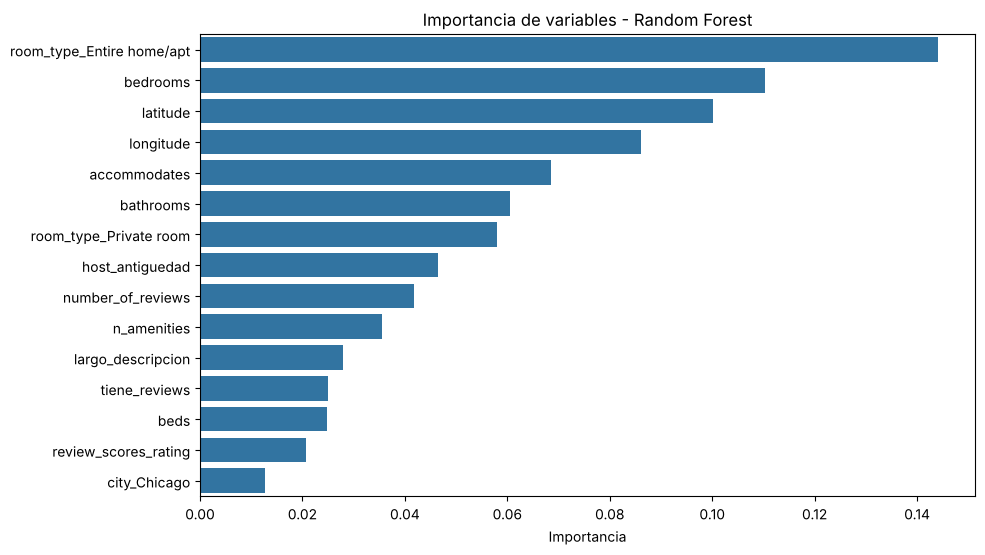

In [39]:
# Importancia de variables del Random Forest (los nombres salen del preprocesador)
importancia = pd.Series(grid_rf.best_estimator_.named_steps['modelo'].feature_importances_, index=nombres_columnas)

importancia = importancia.sort_values(ascending=False).head(15)

plt.figure(figsize=(10,6))
sns.barplot(x=importancia.values, y=importancia.index)
plt.title('Importancia de variables - Random Forest')
plt.xlabel('Importancia')
plt.ylabel('')
plt.show()

In [40]:
# La variable más importante es si se alquila la propiedad entera
# Después vienen el tamaño (bedrooms, accommodates, bathrooms) y la ubicación (latitude, longitude)
# Coincide con lo que vimos en el EDA: tipo de habitación, ubicación y tamaño son lo que más influye en el precio
# Las variables nuevas también aparecen: largo_descripcion y tiene_reviews están entre las 15 más importantes
# Las variables del host y la política de cancelación casi no aportan

# Comparación de modelos

In [41]:
# Tabla con los resultados de todos los modelos
pd.DataFrame(resultados).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Baseline (mediana ciudad x tipo),0.341,0.347,200.564,93.502
1,Regresión lineal,0.579,0.577,164.420,78.073
2,Ridge,0.579,0.577,164.330,78.096
3,Árbol de decisión,0.643,0.590,158.004,76.177
4,Random Forest,0.953,0.660,150.617,68.920
5,LightGBM,0.791,0.668,148.394,68.477


In [42]:
# Todos los modelos le ganan al baseline (R2 0.347), así que el Machine Learning sí aporta
# Los modelos de árboles predicen mejor que los lineales, lo cual indica que la relación entre las variables y el precio no es lineal
# El mejor modelo es LightGBM con R2 test 0.668 y error promedio de 68,5 USD por noche, apenas mejor que el Random Forest (0.660)

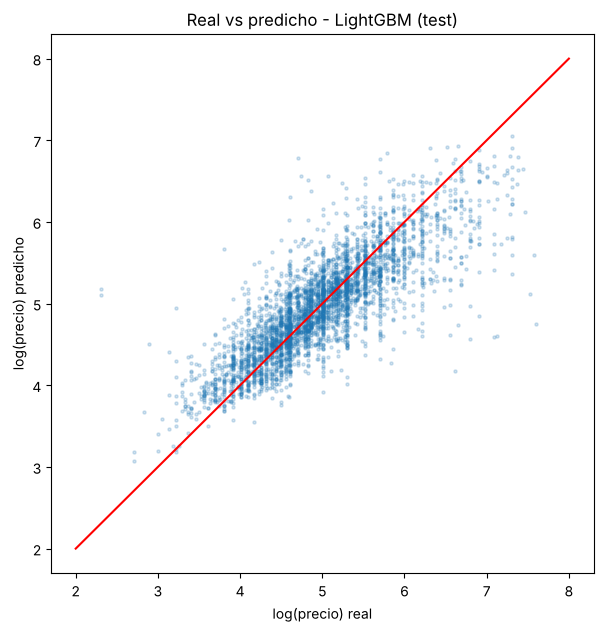

In [43]:
# Gráfico de precio real vs precio predicho por el mejor modelo (LightGBM) en test
pred_lgbm = random_lgbm.best_estimator_.predict(X_test)

plt.figure(figsize=(7,7))
plt.scatter(y_test, pred_lgbm, alpha=0.2, s=5)
# Línea diagonal: si la predicción fuera perfecta, todos los puntos estarían sobre ella
plt.plot([2, 8], [2, 8], color='red')
plt.title('Real vs predicho - LightGBM (test)')
plt.xlabel('log(precio) real')
plt.ylabel('log(precio) predicho')
plt.show()

In [44]:
# Si la predicción fuera perfecta estaría sobre la línea roja
# La mayoría de los puntos sigue la línea, así que el modelo predice bien la tendencia
# Se equivoca más en los extremos. A las propiedades muy caras les predice menos y a las muy baratas les predice más
# El modelo tiende a ir hacia el promedio, sucede porque hay pocos ejemplos en los extremos

# Reducción de la dimensionalidad: PCA

## Varianza explicada

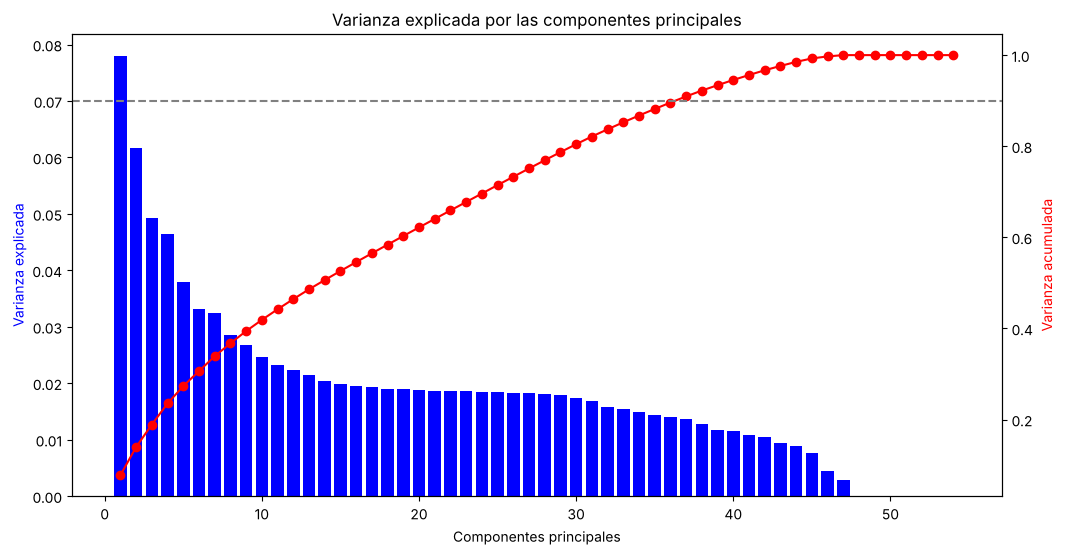

In [45]:
# Aplico PCA con todas las componentes sobre los datos de train ya preprocesados, para ver cuánta varianza explica cada una
pca_completo = PCA()
pca_completo.fit(X_train_prep)

varianza = pca_completo.explained_variance_ratio_
varianza_acum = np.cumsum(varianza)

componentes = range(1, len(varianza) + 1)
fig, ax1 = plt.subplots(figsize=(12,6))
ax1.bar(componentes, varianza, color='blue')
ax1.set_xlabel('Componentes principales')
ax1.set_ylabel('Varianza explicada', color='blue')

ax2 = ax1.twinx()
ax2.plot(componentes, varianza_acum, color='red', marker='o')
ax2.axhline(0.9, color='gray', linestyle='--')
ax2.set_ylabel('Varianza acumulada', color='red')

plt.title('Varianza explicada por las componentes principales')
plt.show()

In [46]:
# Cuántas componentes necesito para explicar el 80%, 90% y 95% de la varianza
print('80%:', (varianza_acum < 0.80).sum() + 1)
print('90%:', (varianza_acum < 0.90).sum() + 1)
print('95%:', (varianza_acum < 0.95).sum() + 1)

# Varianza de las primeras 5 componentes
print(varianza[0:5].round(3))

80%: 30
90%: 37
95%: 41
[0.078 0.062 0.049 0.046 0.038]


In [47]:
# Para explicar el 90% de la varianza se necesitan 37 de las 54 componentes, y para el 95% se necesitan 41
# La primera componente explica solo el 7,8%: la información está bastante repartida entre muchas variables
# Las últimas componentes explican aprox 0%. Son redundantes. Por ejemplo, las dummies de city siempre suman 1, entonces sabiendo 3 ciudades ya sabés la cuarta
# Elegimos quedarnos con el 90% de la varianza: reducimos de 54 a 37 variables perdiendo solo el 10% de la información

## Visualización con 2 componentes

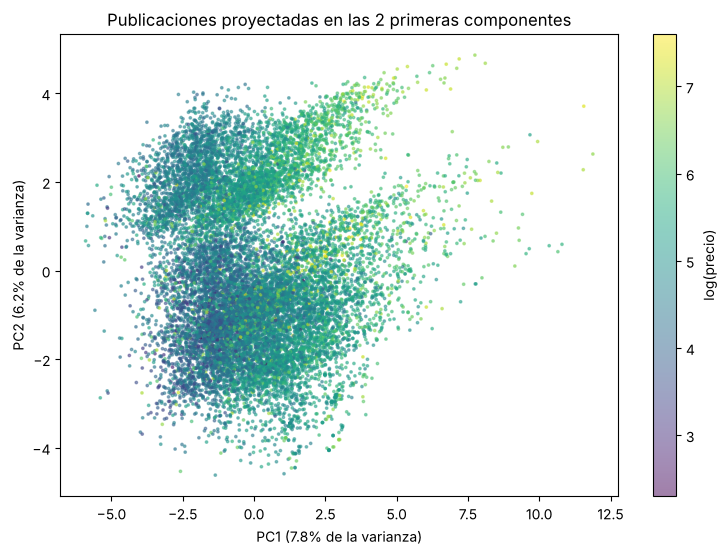

In [48]:
# Proyecto los datos de train en las 2 primeras componentes y los coloreo según el log(precio)
X_train_2pc = pca_completo.transform(X_train_prep)

plt.figure(figsize=(9,6))
plt.scatter(X_train_2pc[:, 0], X_train_2pc[:, 1], c=y_train, cmap='viridis', s=3, alpha=0.5)
plt.colorbar(label='log(precio)')
plt.xlabel(f'PC1 ({varianza[0]*100:.1f}% de la varianza)')
plt.ylabel(f'PC2 ({varianza[1]*100:.1f}% de la varianza)')
plt.title('Publicaciones proyectadas en las 2 primeras componentes')
plt.show()

In [49]:
# Variables con más peso en PC1 y PC2 (autovectores)
pesos = pd.DataFrame(pca_completo.components_[0:2], columns=nombres_columnas, index=['PC1', 'PC2'])
print(pesos.loc['PC1'].sort_values(key=abs, ascending=False).head(6).round(2))
print(pesos.loc['PC2'].sort_values(key=abs, ascending=False).head(6).round(2))

accommodates                 0.40
beds                         0.37
bedrooms                     0.35
room_type_Entire home/apt    0.32
room_type_Private room      -0.30
bathrooms                    0.26
Name: PC1, dtype: float64
city_SF                    0.45
longitude                 -0.45
latitude                  -0.42
city_Boston               -0.28
property_type_House        0.21
property_type_Apartment   -0.21
Name: PC2, dtype: float64


In [50]:
# PC1 está formada por accommodates, beds, bedrooms y room_type. Representa el tamaño de la propiedad
# Por eso el precio aumenta hacia la derecha
# PC2 está formada por city_SF, longitude y latitude. Representa la ubicación
# Por eso se ven 2 grupos: San Francisco arriba y las ciudades del este abajo
# Con solo 2 componentes (que conforman el 14% de la varianza) ya se ven los dos factores más importantes del precio: tamaño y ubicación

## Aplicar PCA

In [51]:
# Cantidad de componentes que explican el 90% de la varianza
n_componentes = (varianza_acum < 0.90).sum() + 1
print(n_componentes)

37


In [52]:
# Nos quedamos con 37 componentes principales en lugar de 54 variables
# El PCA va dentro del Pipeline de cada modelo, después del preprocesador: así se ajusta solo con train (y en cada fold, solo con los datos de entrenamiento de ese fold)
# Cada componente es una combinación de las variables originales, ya no tienen un significado directo (- interpretabilidad)

# Modelos con PCA

## Regresión lineal + PCA

In [53]:
# El PCA va dentro del Pipeline, entre el preprocesador y el modelo
lr_pca = Pipeline([('prep', preprocesador), ('pca', PCA(n_components=n_componentes)), ('modelo', LinearRegression())])
lr_pca.fit(X_train, y_train)

res_lr_pca = evaluar('Regresión lineal + PCA', lr_pca, X_train, X_test)
resultados.append(res_lr_pca)
pd.DataFrame([res_lr_pca]).round(3)

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Regresión lineal + PCA,0.559,0.561,172.998,79.927


## Ridge + PCA

In [54]:
ridge_pca = Pipeline([('prep', preprocesador), ('pca', PCA(n_components=n_componentes)), ('modelo', Ridge())])
grid_ridge_pca = GridSearchCV(ridge_pca, param_ridge, cv=5, scoring='r2')
grid_ridge_pca.fit(X_train, y_train)
print(grid_ridge_pca.best_params_)

res_ridge_pca = evaluar('Ridge + PCA', grid_ridge_pca.best_estimator_, X_train, X_test)
resultados.append(res_ridge_pca)
pd.DataFrame([res_ridge_pca]).round(3)

{'modelo__alpha': 100}


,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Ridge + PCA,0.559,0.561,172.943,79.908


## Árbol de decisión + PCA

In [55]:
arbol_pca = Pipeline([('prep', preprocesador), ('pca', PCA(n_components=n_componentes)), ('modelo', DecisionTreeRegressor(random_state=42))])
grid_arbol_pca = GridSearchCV(arbol_pca, param_arbol, cv=5, scoring='r2')
grid_arbol_pca.fit(X_train, y_train)
print(grid_arbol_pca.best_params_)

res_arbol_pca = evaluar('Árbol de decisión + PCA', grid_arbol_pca.best_estimator_, X_train, X_test)
resultados.append(res_arbol_pca)
pd.DataFrame([res_arbol_pca]).round(3)

{'modelo__max_depth': 10, 'modelo__min_samples_leaf': 50}


,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Árbol de decisión + PCA,0.593,0.504,165.856,82.648


## Random Forest + PCA

In [56]:
rf_pca = Pipeline([('prep', preprocesador), ('pca', PCA(n_components=n_componentes)),
                   ('modelo', RandomForestRegressor(n_estimators=100, max_features=0.33, random_state=42, n_jobs=-1))])
grid_rf_pca = GridSearchCV(rf_pca, param_rf, cv=3, scoring='r2')
grid_rf_pca.fit(X_train, y_train)
print(grid_rf_pca.best_params_)

res_rf_pca = evaluar('Random Forest + PCA', grid_rf_pca.best_estimator_, X_train, X_test)
resultados.append(res_rf_pca)
pd.DataFrame([res_rf_pca]).round(3)

{'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}


,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Random Forest + PCA,0.838,0.599,159.434,75.173


## LightGBM + PCA

In [57]:
lgbm_pca = Pipeline([('prep', preprocesador), ('pca', PCA(n_components=n_componentes)),
                     ('modelo', lgb.LGBMRegressor(random_state=42, verbose=-1))])
random_lgbm_pca = RandomizedSearchCV(lgbm_pca, param_lgbm, n_iter=15, cv=3, scoring='r2', random_state=42)
random_lgbm_pca.fit(X_train, y_train)
print(random_lgbm_pca.best_params_)

res_lgbm_pca = evaluar('LightGBM + PCA', random_lgbm_pca.best_estimator_, X_train, X_test)
resultados.append(res_lgbm_pca)
pd.DataFrame([res_lgbm_pca]).round(3)

{'modelo__num_leaves': 15, 'modelo__n_estimators': 600, 'modelo__min_child_samples': 20, 'modelo__learning_rate': 0.03}


,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,LightGBM + PCA,0.708,0.599,156.926,75.558


In [58]:
# Con PCA todos los modelos empeoran
# Regresión lineal y Ridge: R2 test baja de 0.577 a 0.561
# Árbol de decisión: baja de 0.590 a 0.504
# Random Forest: baja de 0.660 a 0.599
# LightGBM: baja de 0.668 a 0.599
# Los modelos de árboles son los que más empeoran

## Cantidad de componentes vs desempeño

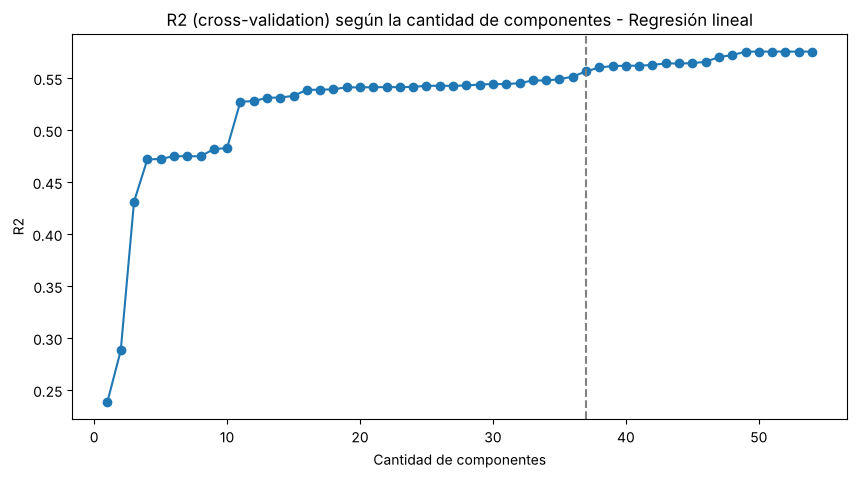

In [59]:
# Pruebo la regresión lineal con distinta cantidad de componentes (de 1 a todas)
# Uso cross-validation sobre train para no tocar el test
n_total = X_train_prep.shape[1]
lista_r2 = []
for n in range(1, n_total + 1):
    X_n = pca_completo.transform(X_train_prep)[:, 0:n]
    r2 = cross_val_score(LinearRegression(), X_n, y_train, cv=5, scoring='r2').mean()
    lista_r2.append(r2)

plt.figure(figsize=(10,5))
plt.plot(range(1, n_total + 1), lista_r2, marker='o')
plt.axvline(n_componentes, color='gray', linestyle='--')
plt.title('R2 (cross-validation) según la cantidad de componentes - Regresión lineal')
plt.xlabel('Cantidad de componentes')
plt.ylabel('R2')
plt.show()

In [60]:
# Con pocas componentes el R2 es bajo, y va subiendo a medida que agregamos más
# Con 11 componentes ya se llega a 0.53, después la mejora es muy lenta
# Con 37 componentes (línea gris) el R2 es 0.56, y recién con unas 49 se llega al R2 del modelo sin PCA (0.575)
# Las componentes que explican poca varianza también tienen información útil para predecir el precio

# Comparación final

In [61]:
# Tabla con todos los resultados
tabla_final = pd.DataFrame(resultados).round(3)
tabla_final

,Modelo,R2 train,R2 test,RMSE (USD),MAE (USD)
0,Baseline (mediana ciudad x tipo),0.341,0.347,200.564,93.502
1,Regresión lineal,0.579,0.577,164.420,78.073
2,Ridge,0.579,0.577,164.330,78.096
3,Árbol de decisión,0.643,0.590,158.004,76.177
4,Random Forest,0.953,0.660,150.617,68.920
5,LightGBM,0.791,0.668,148.394,68.477
6,Regresión lineal + PCA,0.559,0.561,172.998,79.927
7,Ridge + PCA,0.559,0.561,172.943,79.908
8,Árbol de decisión + PCA,0.593,0.504,165.856,82.648
9,Random Forest + PCA,0.838,0.599,159.434,75.173


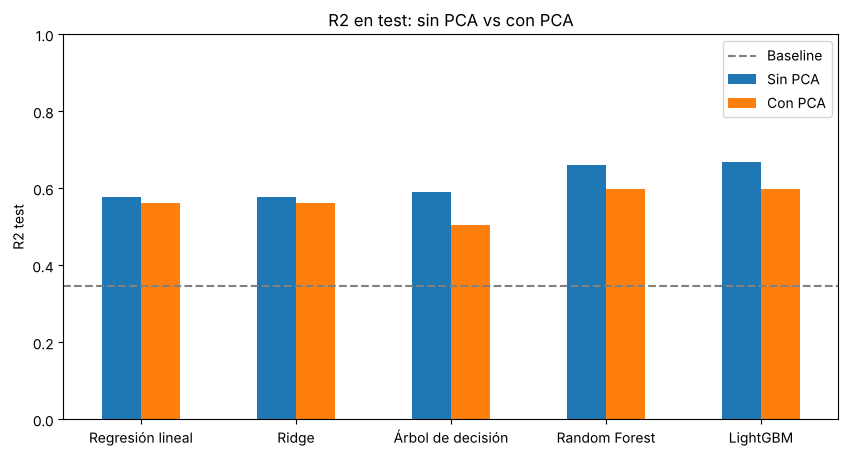

In [62]:
# Comparo el R2 en test de cada modelo sin PCA y con PCA (el baseline no tiene versión con PCA)
comparacion = pd.DataFrame({'Sin PCA': tabla_final['R2 test'][1:6].values,
                            'Con PCA': tabla_final['R2 test'][6:11].values},
                           index=['Regresión lineal', 'Ridge', 'Árbol de decisión', 'Random Forest', 'LightGBM'])

comparacion.plot(kind='bar', figsize=(10,5))
plt.axhline(tabla_final['R2 test'][0], color='gray', linestyle='--', label='Baseline')
plt.title('R2 en test: sin PCA vs con PCA')
plt.ylabel('R2 test')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend()
plt.show()

In [63]:
# PCA redujo la cantidad de variables un 31% (de 54 a 37) pero todos los modelos predicen peor
# Esto puede pasar porque PCA es no supervisado. Elige las componentes que tienen más varianza en X, sin mirar el precio
# Entonces descarta componentes con poca varianza que sí servían para predecir el precio
# La diferencia entre con PCA y sin PCA es mayor en los árboles porque los árboles aprovechan cortes simples sobre una variable
# Con PCA cada componente mezcla muchas variables y esos cortes se pierden
# Nuestros datos no tienen tanta redundancia: la primera componente explica solo el 7,8% de la varianza
# Aun con PCA, todos los modelos siguen superando al baseline
# Conclusión: en este problema conviene usar las variables originales. PCA sería útil si tuviéramos muchas más variables o si necesitáramos un modelo más rápido

# Conclusiones

In [64]:
# - El mejor modelo es LightGBM sin PCA: explica el 66,8% de la variación del precio y se equivoca en promedio 68,5 USD por noche
# - Todos los modelos superan al baseline de la mediana por ciudad y tipo de habitación (R2 0.347), así que el Machine Learning aporta
# - Los modelos de árboles superan a los lineales, porque la relación entre las variables y el precio no es lineal
# - Ridge no mejora a la regresión lineal porque el modelo lineal no tenía overfitting
# - Las variables más importantes son el tipo de habitación, la ubicación y el tamaño de la propiedad, igual que en el EDA
# - PCA redujo las variables de 54 a 37 manteniendo el 90% de la varianza, pero empeoró todos los modelos